In [ ]:
%pip install datasets
%pip install evaluate
%pip install accelerate -U

Đã đọc: C:\Users\HCMBK\Downloads\DeepLearningandItsApplicationsinComputerVision\Projects\CO5085-Image-Segmentation\A1\data\pathmnist.npz


,class_id,class_name,train,val,test
0,0,Adipose,9366,1041,1338
1,1,Background,9509,1057,847
2,2,Debris,10360,1152,339
3,3,Lymphocytes,10401,1156,634
4,4,Mucus,8006,890,1035
5,5,Smooth muscle,12182,1354,592
6,6,Normal colon mucosa,7886,877,741
7,7,Cancer-associated stroma,9401,1045,421
8,8,Colorectal adenocarcinoma epithelium,12885,1432,1233


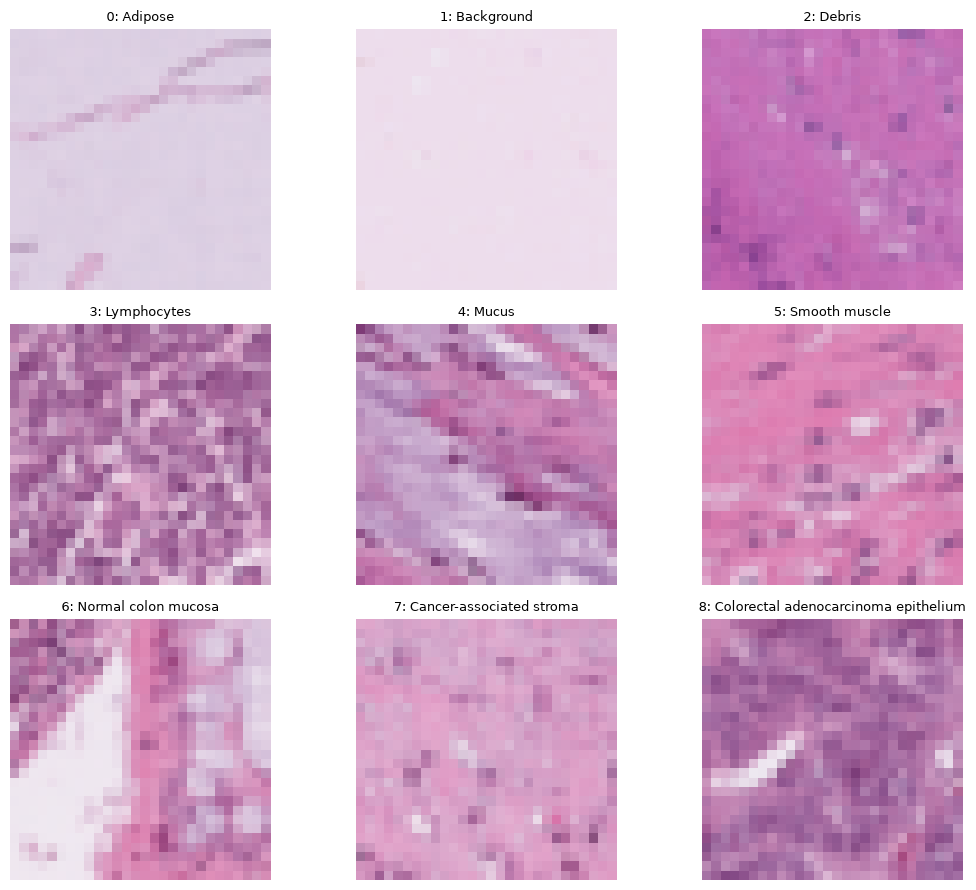

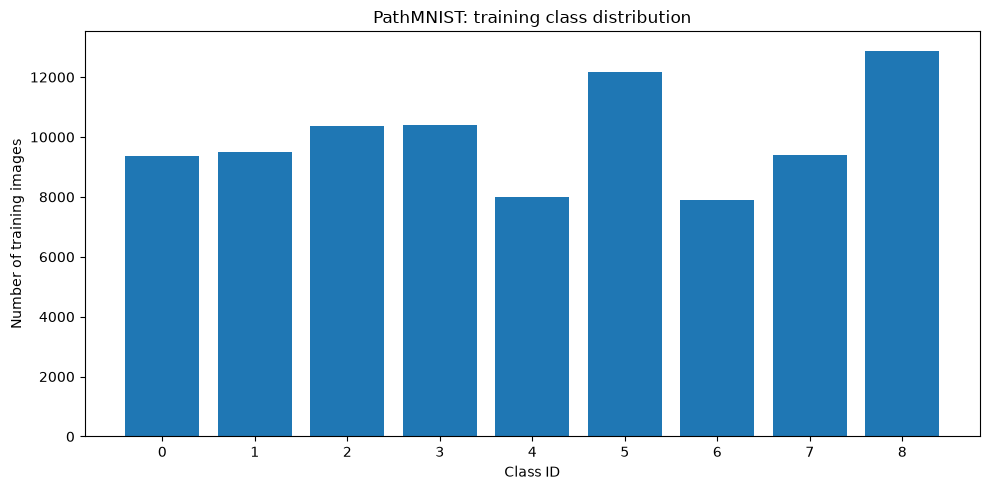

Đã lưu tại: C:\Users\HCMBK\Downloads\DeepLearningandItsApplicationsinComputerVision\Projects\CO5085-Image-Segmentation\A1\results


In [5]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# 1. Khai báo đường dẫn và đọc dữ liệu trước
data_path = Path(
    r"C:\Users\HCMBK\Downloads\DeepLearningandItsApplicationsinComputerVision"
    r"\Projects\CO5085-Image-Segmentation\A1\data\pathmnist.npz"
)

if not data_path.is_file():
    raise FileNotFoundError(f"Không tìm thấy: {data_path}")

data = np.load(data_path, allow_pickle=False)
print("Đã đọc:", data_path)

# 2. Tạo thư mục lưu kết quả
results_dir = data_path.parent.parent / "results"
results_dir.mkdir(parents=True, exist_ok=True)

class_names = [
    "Adipose", "Background", "Debris",
    "Lymphocytes", "Mucus", "Smooth muscle",
    "Normal colon mucosa", "Cancer-associated stroma",
    "Colorectal adenocarcinoma epithelium"
]

# 3. Thống kê số ảnh mỗi lớp
stats = pd.DataFrame({
    "class_id": range(9),
    "class_name": class_names
})

for split in ["train", "val", "test"]:
    labels = data[f"{split}_labels"].reshape(-1)
    stats[split] = [
        int((labels == class_id).sum())
        for class_id in range(9)
    ]

stats.to_csv(
    results_dir / "class_distribution.csv",
    index=False,
    encoding="utf-8-sig"
)
display(stats)

# 4. Hiển thị một ảnh train đại diện mỗi lớp
images = data["train_images"]
labels = data["train_labels"].reshape(-1)

fig, axes = plt.subplots(3, 3, figsize=(11, 9))

for class_id, ax in enumerate(axes.flat):
    indices = np.flatnonzero(labels == class_id)
    if len(indices):
        ax.imshow(images[indices[0]])

    ax.set_title(f"{class_id}: {class_names[class_id]}", fontsize=9)
    ax.axis("off")

fig.tight_layout()
fig.savefig(results_dir / "sample_images.png", dpi=200)
plt.show()
plt.close(fig)

# 5. Biểu đồ phân bố lớp trên tập train
fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(stats["class_id"].astype(str), stats["train"])
ax.set_xlabel("Class ID")
ax.set_ylabel("Number of training images")
ax.set_title("PathMNIST: training class distribution")

fig.tight_layout()
fig.savefig(results_dir / "train_class_distribution.png", dpi=200)
plt.show()
plt.close(fig)

data.close()
print("Đã lưu tại:", results_dir)

## A1.1 — Dataset và kế hoạch thí nghiệm

### 1. Đề tài
So sánh CNN và Vision Transformer trong phân loại ảnh mô bệnh học:
ảnh hưởng của pretrained và chiến lược đóng băng backbone.

### 2. Dataset
- PathMNIST: 107.180 ảnh RGB, 9 lớp.
- Train: 89.996 ảnh.
- Validation: 10.004 ảnh.
- Test: 7.180 ảnh.
- Ảnh lưu trữ: 28 × 28; resize lên 224 × 224 khi đưa vào mô hình.
- Giữ nguyên split được cung cấp.
- Dataset có 9 lớp, thấp hơn mức ưu tiên ≥ 10 lớp của đề;
  lựa chọn nhằm gắn với paper tái lập và có quy mô dữ liệu đủ lớn.

### 3. Mô hình dự kiến
- CNN baseline: ResNet-18.
- Transformer: ViT-Base/16, theo paper đã chọn.
- Kiểm tra bộ nhớ bằng một bước forward/backward trước khi train chính thức.
- Huấn luyện lần lượt từng mô hình trên GPU.

### 4. Kế hoạch thí nghiệm
Với mỗi mô hình:
1. Khởi tạo ngẫu nhiên, train toàn bộ.
2. Pretrained, chỉ train classification head.
3. Pretrained, mở khóa phần cuối backbone và head.
4. Pretrained, fine-tune toàn bộ.

Phạm vi mở khóa một phần:
- ResNet-18: layer4 và fc.
- ViT-Base: 2 encoder block cuối, layernorm cuối và classifier.

### 5. Tiền xử lý và augmentation
- Train: resize 224 × 224, lật ngang ngẫu nhiên.
- Validation/test: resize 224 × 224, không augmentation ngẫu nhiên.
- Chuẩn hóa theo cấu hình pretrained của từng mô hình;
  dùng cùng cấu hình chuẩn hóa cho bản from-scratch tương ứng.
- Seed dự kiến: 42.

### 6. Đánh giá
- Accuracy, Macro-F1 và confusion matrix.
- Thời gian huấn luyện, VRAM đỉnh, số tham số tổng và trainable.
- Chọn checkpoint theo validation Macro-F1.
- Không dùng test để chọn cấu hình hoặc checkpoint.

### 7. Trạng thái
Đã kiểm tra môi trường GPU, đọc dữ liệu và tạo hình EDA.
Chưa có kết quả huấn luyện hoặc so sánh mô hình.

In [6]:
import gc
import torch
from transformers import ViTForImageClassification

if not torch.cuda.is_available():
    raise RuntimeError("Chưa nhận GPU.")

gc.collect()
torch.cuda.empty_cache()
torch.cuda.reset_peak_memory_stats()

model = None
optimizer = None
x = None
y = None
loss = None

try:
    model = ViTForImageClassification.from_pretrained(
        "google/vit-base-patch16-224",
        num_labels=9,
        ignore_mismatched_sizes=True
    ).cuda()

    model.train()
    optimizer = torch.optim.AdamW(model.parameters(), lr=1e-5)
    scaler = torch.amp.GradScaler("cuda")

    # Batch 1 để kiểm tra khả năng chạy trước
    x = torch.randn(1, 3, 224, 224, device="cuda")
    y = torch.tensor([0], dtype=torch.long, device="cuda")

    optimizer.zero_grad(set_to_none=True)

    with torch.autocast(device_type="cuda", dtype=torch.float16):
        loss = model(pixel_values=x, labels=y).loss

    scaler.scale(loss).backward()
    scaler.step(optimizer)
    scaler.update()
    torch.cuda.synchronize()

    peak = torch.cuda.max_memory_allocated() / 1024**3

    print("Forward + backward + optimizer step: OK")
    print("Loss thử:", loss.item())
    print(f"VRAM đỉnh PyTorch cấp phát: {peak:.2f} GB")

except torch.cuda.OutOfMemoryError:
    print("Không đủ VRAM cho cấu hình full fine-tune thử nghiệm.")

finally:
    model = optimizer = x = y = loss = None
    gc.collect()
    torch.cuda.empty_cache()

c:\Users\HCMBK\Downloads\DeepLearningandItsApplicationsinComputerVision\Projects\CO5085-Image-Segmentation\A1\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
c:\Users\HCMBK\Downloads\DeepLearningandItsApplicationsinComputerVision\Projects\CO5085-Image-Segmentation\A1\.venv\Lib\site-packages\huggingface_hub\file_download.py:143: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\HCMBK\.cache\huggingface\hub\models--google--vit-base-patch16-224. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hu

Forward + backward + optimizer step: OK
Loss thử: 2.4765625
VRAM đỉnh PyTorch cấp phát: 0.67 GB


In [7]:
from pathlib import Path
import numpy as np
import torch
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

# 1. Đọc dữ liệu
data_path = Path(
    r"C:\Users\HCMBK\Downloads\DeepLearningandItsApplicationsinComputerVision"
    r"\Projects\CO5085-Image-Segmentation\A1\data\pathmnist.npz"
)

if not data_path.is_file():
    raise FileNotFoundError(data_path)

# Cấu hình tiền xử lý chung cho phép kiểm tra pipeline
mean = (0.5, 0.5, 0.5)
std = (0.5, 0.5, 0.5)

train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ToTensor(),
    transforms.Normalize(mean, std),
])

val_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean, std),
])

# 2. Dataset: resize từng ảnh khi cần, không resize cả tập vào RAM
class PathMNISTDataset(Dataset):
    def __init__(self, npz_path, split, transform):
        with np.load(npz_path, allow_pickle=False) as archive:
            self.images = archive[f"{split}_images"]
            self.labels = archive[f"{split}_labels"].reshape(-1)

        self.transform = transform

        assert len(self.images) == len(self.labels)
        assert self.labels.min() >= 0
        assert self.labels.max() <= 8

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, index):
        image = Image.fromarray(self.images[index]).convert("RGB")
        image = self.transform(image)
        label = torch.tensor(int(self.labels[index]), dtype=torch.long)
        return image, label

# 3. Tạo tập train/validation
train_dataset = PathMNISTDataset(
    data_path, "train", train_transform
)
val_dataset = PathMNISTDataset(
    data_path, "val", val_transform
)

generator = torch.Generator().manual_seed(42)

train_loader = DataLoader(
    train_dataset,
    batch_size=2,
    shuffle=True,
    num_workers=0,
    pin_memory=torch.cuda.is_available(),
    generator=generator,
)

val_loader = DataLoader(
    val_dataset,
    batch_size=2,
    shuffle=False,
    num_workers=0,
    pin_memory=torch.cuda.is_available(),
)

# 4. Kiểm tra một batch
images, labels = next(iter(train_loader))

assert images.shape == (2, 3, 224, 224)
assert labels.dtype == torch.long
assert torch.isfinite(images).all()

print("Train:", len(train_dataset))
print("Validation:", len(val_dataset))
print("Batch ảnh:", images.shape)
print("Batch nhãn:", labels)
print("Kiểu nhãn:", labels.dtype)
print("DataLoader: OK")

Train: 89996
Validation: 10004
Batch ảnh: torch.Size([2, 3, 224, 224])
Batch nhãn: tensor([3, 8])
Kiểu nhãn: torch.int64
DataLoader: OK


In [8]:
import time
import json
import torch
from itertools import islice
from pathlib import Path
from transformers import ViTForImageClassification

if not torch.cuda.is_available():
    raise RuntimeError("Chưa nhận GPU.")

torch.manual_seed(42)
torch.cuda.manual_seed_all(42)

device = torch.device("cuda")

model = ViTForImageClassification.from_pretrained(
    "google/vit-base-patch16-224",
    num_labels=9,
    ignore_mismatched_sizes=True
).to(device)

optimizer = torch.optim.AdamW(model.parameters(), lr=1e-5)
scaler = torch.amp.GradScaler("cuda")

torch.cuda.reset_peak_memory_stats()
torch.cuda.synchronize()
start = time.perf_counter()

# 1. Train thử 20 batch
model.train()
train_loss_sum = 0.0
train_samples = 0
train_steps = 0

for images, labels in islice(train_loader, 20):
    images = images.to(device, non_blocking=True)
    labels = labels.to(device, non_blocking=True)

    optimizer.zero_grad(set_to_none=True)

    with torch.autocast("cuda", dtype=torch.float16):
        loss = model(pixel_values=images, labels=labels).loss

    if not torch.isfinite(loss):
        raise RuntimeError("Loss không hữu hạn.")

    scaler.scale(loss).backward()
    scaler.step(optimizer)
    scaler.update()

    n = labels.size(0)
    train_loss_sum += loss.item() * n
    train_samples += n
    train_steps += 1

    print(f"Train batch {train_steps:02d}/20 | loss={loss.item():.4f}")

# 2. Validation thử 10 batch, không cập nhật trọng số
model.eval()
val_loss_sum = 0.0
val_correct = 0
val_samples = 0

with torch.inference_mode():
    for images, labels in islice(val_loader, 10):
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        with torch.autocast("cuda", dtype=torch.float16):
            outputs = model(pixel_values=images, labels=labels)

        if not torch.isfinite(outputs.loss):
            raise RuntimeError("Validation loss không hữu hạn.")

        n = labels.size(0)
        val_loss_sum += outputs.loss.item() * n
        val_correct += (outputs.logits.argmax(1) == labels).sum().item()
        val_samples += n

torch.cuda.synchronize()

summary = {
    "purpose": "pipeline_check_only",
    "train_batches": train_steps,
    "train_samples": train_samples,
    "validation_samples": val_samples,
    "train_loss": train_loss_sum / train_samples,
    "validation_loss": val_loss_sum / val_samples,
    "validation_subset_accuracy": val_correct / val_samples,
    "elapsed_seconds": time.perf_counter() - start,
    "peak_allocated_vram_gb":
        torch.cuda.max_memory_allocated() / 1024**3
}

# 3. Lưu bằng chứng kiểm tra
results_dir = data_path.parent.parent / "results"
results_dir.mkdir(parents=True, exist_ok=True)

output_path = results_dir / "vit_pipeline_check.json"
output_path.write_text(
    json.dumps(summary, indent=2),
    encoding="utf-8"
)

print("\nPIPELINE CHECK: OK")
print(json.dumps(summary, indent=2))
print("Đã lưu:", output_path)

Some weights of ViTForImageClassification were not initialized from the model checkpoint at google/vit-base-patch16-224 and are newly initialized because the shapes did not match:
- classifier.bias: found shape torch.Size([1000]) in the checkpoint and torch.Size([9]) in the model instantiated
- classifier.weight: found shape torch.Size([1000, 768]) in the checkpoint and torch.Size([9, 768]) in the model instantiated
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Train batch 01/20 | loss=2.2393
Train batch 02/20 | loss=2.5400
Train batch 03/20 | loss=2.9697
Train batch 04/20 | loss=2.3809
Train batch 05/20 | loss=2.0850
Train batch 06/20 | loss=2.3594
Train batch 07/20 | loss=2.3252
Train batch 08/20 | loss=2.3188
Train batch 09/20 | loss=1.9668
Train batch 10/20 | loss=2.1045
Train batch 11/20 | loss=2.4067
Train batch 12/20 | loss=2.9736
Train batch 13/20 | loss=2.3931
Train batch 14/20 | loss=2.4048
Train batch 15/20 | loss=1.9634
Train batch 16/20 | loss=2.0879
Train batch 17/20 | loss=2.3555
Train batch 18/20 | loss=2.1509
Train batch 19/20 | loss=2.5469
Train batch 20/20 | loss=2.0762

PIPELINE CHECK: OK
{
  "purpose": "pipeline_check_only",
  "train_batches": 20,
  "train_samples": 40,
  "validation_samples": 20,
  "train_loss": 2.332421875,
  "validation_loss": 2.290478515625,
  "validation_subset_accuracy": 0.0,
  "elapsed_seconds": 2.1233780999900773,
  "peak_allocated_vram_gb": 1.6227216720581055
}
Đã lưu: C:\Users\HCMBK\Downloads\De

In [2]:
import requests
import torch
from PIL import Image
from transformers import ViTImageProcessor, ViTForImageClassification, TrainingArguments
from tqdm import tqdm

device = "cpu"

In [3]:
model_name = "google/vit-base-patch16-224"                        # the model name
image_processor = ViTImageProcessor.from_pretrained(model_name)   # load the image processor
model = ViTForImageClassification.from_pretrained(model_name)     # loading the pre-trained model

/usr/local/lib/python3.10/dist-packages/huggingface_hub/utils/_token.py:72: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


preprocessor_config.json:   0%|          | 0.00/160 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/69.7k [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/346M [00:00<?, ?B/s]

**Load Dataset**

In [4]:
from datasets import load_dataset

ds = load_dataset("albertvillanova/medmnist-v2", "pathmnist")    # download & load the dataset

Generating train split:   0%|          | 0/89996 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/10004 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/7180 [00:00<?, ? examples/s]

In [5]:
labels = ds["train"].features["label"]
labels

ClassLabel(names=['adipose', 'background', 'debris', 'lymphocytes', 'mucus', 'smooth muscle', 'normal colon mucosa', 'cancer-associated stroma', 'colorectal adenocarcinoma epithelium'], id=None)

**Data Preprocessing**

In [6]:
def transform(examples):
  # convert all images to RGB format, then preprocessing it using our image processor
  inputs = image_processor([img.convert("RGB") for img in examples["image"]], return_tensors="pt")

  # we also shouldn't forget about the labels
  inputs["labels"] = examples["label"]

  return inputs

# use the with_transform() method to apply the transform to the dataset on the fly during training
dataset = ds.with_transform(transform)

In [7]:
import matplotlib.pyplot as plt
def show_image(dataset, split, index):
    data = dataset[split][index]
    if "image" in data:  # Original dataset
        image = data["image"]
        label = data["label"]

        plt.figure(figsize=(1, 1))
        plt.imshow(image)
        plt.axis('off')
        plt.title(f"Class {label}", fontsize=8)
        plt.show()
    else:  # Transformed dataset
        image_tensor = data['pixel_values']
        label = data['labels']

        # Convert the tensor to a NumPy array and display the image
        image_array = image_tensor.numpy()  # Convert the torch tensor to a NumPy array
        plt.figure(figsize=(1, 1))
        plt.imshow(image_array.transpose(1, 2, 0))  # Matplotlib expects the channel dimension last
        plt.title(f"Class {label}", fontsize=8)
        plt.axis('off')  # Hide the axis
        plt.show()

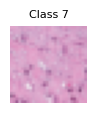

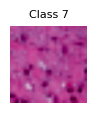

In [8]:
idx = 2
show_image(ds, "train", idx)
show_image(dataset, "train", idx)

In [9]:
for item in dataset["train"]:
  print(item["pixel_values"].shape)
  print(item["labels"])
  break

torch.Size([3, 224, 224])
0


In [10]:
labels = ds["train"].features["label"].names

def collate_fn(batch):
  return {
      "pixel_values": torch.stack([x["pixel_values"] for x in batch]),
      "labels": torch.tensor([x["labels"] for x in batch]),
  }

In [11]:
from evaluate import load
import numpy as np

# load the accuracy and f1 metrics from the evaluate module
accuracy = load("accuracy")
f1 = load("f1")

def compute_metrics(eval_pred):
  # compute the accuracy and f1 scores & return them
  accuracy_score = accuracy.compute(predictions=np.argmax(eval_pred.predictions, axis=1), references=eval_pred.label_ids)
  f1_score = f1.compute(predictions=np.argmax(eval_pred.predictions, axis=1), references=eval_pred.label_ids, average="macro")
  return {**accuracy_score, **f1_score}

In [12]:
# load the ViT model
model = ViTForImageClassification.from_pretrained(
    model_name,
    num_labels=len(labels),
    id2label={str(i): c for i, c in enumerate(labels)},
    label2id={c: str(i) for i, c in enumerate(labels)},
    ignore_mismatched_sizes=True,
)

/usr/local/lib/python3.10/dist-packages/huggingface_hub/utils/_token.py:72: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(
Some weights of ViTForImageClassification were not initialized from the model checkpoint at google/vit-base-patch16-224 and are newly initialized because the shapes did not match:
- classifier.bias: found shape torch.Size([1000]) in the checkpoint and torch.Size([9]) in the model instantiated
- classifier.weight: found shape torch.Size([1000, 768]) in the checkpoint and torch.Size([9, 768]) in the model instantiated
You should probably TRAIN this model on a down-stream task to

In [13]:
import accelerate
import transformers

transformers.__version__, accelerate.__version__

('4.35.2', '0.25.0')

In [14]:
# defining the training arguments
training_args = TrainingArguments(
  output_dir="./vit-base-food", # output directory
  # output_dir="./vit-base-skin-cancer",
  per_device_train_batch_size=32, # batch size per device during training
  evaluation_strategy="steps",    # evaluation strategy to adopt during training
  num_train_epochs=2,             # total number of training epochs
  # fp16=True,                    # use mixed precision
  save_steps=200,                # number of update steps before saving checkpoint
  eval_steps=200,                # number of update steps before evaluating
  logging_steps=200,             # number of update steps before logging
  # save_steps=50,
  # eval_steps=50,
  # logging_steps=50,
  save_total_limit=2,             # limit the total amount of checkpoints on disk
  remove_unused_columns=False,    # remove unused columns from the dataset
  push_to_hub=False,              # do not push the model to the hub
  report_to='tensorboard',        # report metrics to tensorboard
  load_best_model_at_end=True,    # load the best model at the end of training
)


In [15]:
# Create Trainer
from transformers import Trainer

trainer = Trainer(
    model=model,                        # the instantiated 🤗 Transformers model to be trained
    args=training_args,                 # training arguments, defined above
    data_collator=collate_fn,           # the data collator that will be used for batching
    compute_metrics=compute_metrics,    # the metrics function that will be used for evaluation
    train_dataset=dataset["train"],     # training dataset
    eval_dataset=dataset["validation"], # evaluation dataset
    tokenizer=image_processor,          # the processor that will be used for preprocessing the images
)

In [16]:
trainer.train()

Step,Training Loss,Validation Loss,Accuracy,F1
200,0.399800,0.190093,0.937925,0.938946
400,0.174600,0.152562,0.950320,0.951807
600,0.146800,0.119755,0.961915,0.961530
800,0.116100,0.101316,0.970012,0.969280
1000,0.112200,0.077255,0.974710,0.974758
1200,0.098200,0.086738,0.973211,0.973373
1400,0.089700,0.068246,0.979408,0.979476
1600,0.069500,0.069010,0.978009,0.977652
1800,0.073600,0.054026,0.983007,0.982844
2000,0.070800,0.053383,0.983806,0.983887


TrainOutput(global_step=5626, training_loss=0.06492874516823773, metrics={'train_runtime': 11893.7975, 'train_samples_per_second': 15.133, 'train_steps_per_second': 0.473, 'total_flos': 1.3948813271417537e+19, 'train_loss': 0.06492874516823773, 'epoch': 2.0})

In [17]:
trainer.evaluate(dataset["test"])

{'eval_loss': 0.23923079669475555,
 'eval_accuracy': 0.9462395543175487,
 'eval_f1': 0.9301018294225432,
 'eval_runtime': 115.5509,
 'eval_samples_per_second': 62.137,
 'eval_steps_per_second': 7.771,
 'epoch': 2.0}

**Evaluation with Confusion Matrix**

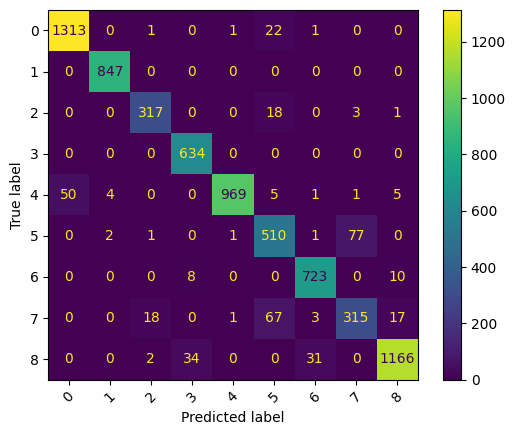

In [18]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

outputs = trainer.predict(dataset["test"])
y_true = outputs.label_ids
y_pred = outputs.predictions.argmax(1)

labels = dataset["train"].features['label'].names
cm = confusion_matrix(y_true, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm)
# disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=labels)
disp.plot(xticks_rotation=45)

**Generate Precision, Recall, F1 Score, Support**

In [19]:
from sklearn.metrics import precision_recall_fscore_support

precision, recall, f1_score, support = precision_recall_fscore_support(y_true, y_pred, average=None)
precision, recall, f1_score, support

(array([0.96331621, 0.992966  , 0.93510324, 0.93786982, 0.99691358,
        0.81993569, 0.95131579, 0.79545455, 0.97247706]),
 array([0.9813154 , 1.        , 0.93510324, 1.        , 0.93623188,
        0.86148649, 0.9757085 , 0.74821853, 0.94566099]),
 array([0.97223251, 0.99647059, 0.93510324, 0.96793893, 0.96562033,
        0.84019769, 0.96335776, 0.77111383, 0.95888158]),
 array([1338,  847,  339,  634, 1035,  592,  741,  421, 1233]))

**Generate Training & Loss Curves**

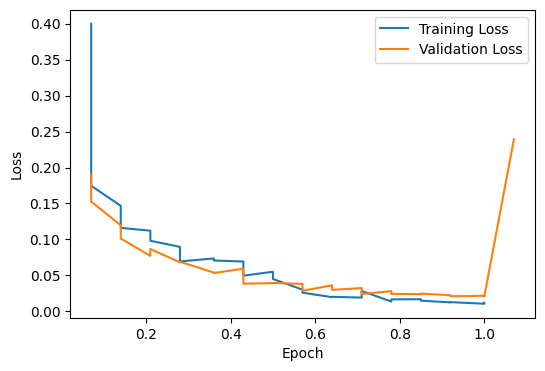

In [20]:
import matplotlib.pyplot as plt

data = trainer.state.log_history
# Extracting data for plotting
epochs = [entry['epoch'] for entry in data]  # Extract epoch values
train_losses = [entry['loss'] for entry in data if 'loss' in entry]  # Extract training losses
eval_losses = [entry['eval_loss'] for entry in data if 'eval_loss' in entry]  # Extract evaluation losses

# Plotting training and evaluation metrics
plt.figure(figsize=(6, 4))

plt.plot(epochs[:len(train_losses)], train_losses, label='Training Loss')
plt.plot(epochs[:len(eval_losses)], eval_losses, label='Validation Loss')

plt.xlabel('Epoch')
plt.ylabel('Loss')
# plt.title('Training and Evaluation Metrics Across Epochs')
plt.legend()
# plt.grid(True)
plt.show()

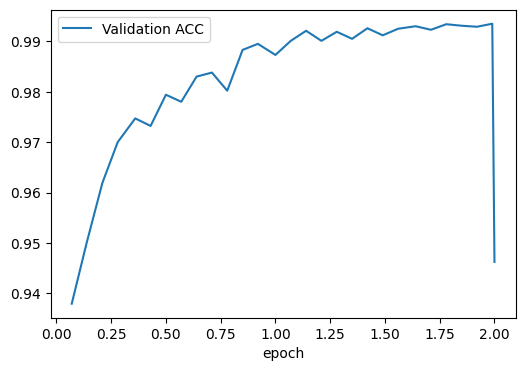

In [21]:
import pandas as pd

loghistory = pd.DataFrame(trainer.state.log_history)
loghistory = loghistory.fillna(0)
loghistory = loghistory.groupby(['epoch']).sum()
fig, ax = plt.subplots(figsize=(6, 4))  # Set the size here (width, height)
loghistory[["eval_accuracy"]].plot(subplots=True, ax=ax)
handles, labels = ax.get_legend_handles_labels()
ax.legend(handles=handles, labels=['Validation ACC'], loc='best')
plt.show()  # Display the plot

**Plot ROC Curves**

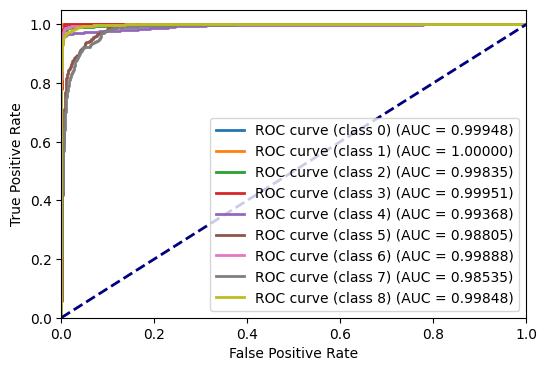

In [22]:
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt
import numpy as np

# Assuming you have predictions and true labels for multi-class classification
# predictions shape: (num_samples, num_classes), where each row contains class probabilities
# true_labels shape: (num_samples,), where each value represents the true class label
true_labels = outputs.label_ids
predictions = outputs.predictions

# Compute ROC curve for each class
num_classes = predictions.shape[1]  # Number of classes
fpr = dict()
tpr = dict()
roc_auc = dict()

for i in range(num_classes):
    fpr[i], tpr[i], _ = roc_curve((true_labels == i).astype(int), predictions[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])

# Plot ROC curve for each class
plt.figure(figsize=(6, 4))

for i in range(num_classes):
    plt.plot(fpr[i], tpr[i], lw=2, label='ROC curve (class %d) (AUC = %0.5f)' % (i, roc_auc[i]))

plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.legend(loc="lower right")
plt.show()